# Part 1.5: Relationships and predictor overlap

What can the candidate predictors tell us? Five questions, all asked **within state and year** (state means and year means
removed), because the models in Part 2 estimate within-state variation and because levels are dominated by permanent
differences between states (73 percent of the variance of the target):

1. How much do the candidate predictors overlap (multicollinearity)?
2. Which predictors, known at the forecast origin, relate to next year's change in severe burden?
3. Which relate to next year's rent growth, the series that has real signal?
4. What is the timing: do predictors lead the burden or move with it?
5. Do the relationships survive leaving out 2021 to 2023, and do predictors that share a source with the target behave
   differently, as the exclusion rules assume?

Features are taken exactly as the forecasting harness takes them (`src/features.py`), at the origin year with their
publication lags, so nothing here uses information a forecaster would not have had.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from features import make_supervised, FEATURE_SETS, FEATURE_LAG
from panel_tools import two_way_demean, cluster_bootstrap_corr, vif
from viz import apply_style, SERIES, DIVERGING, save_figure, SURFACE, INK_2, MUTED, BASELINE, end_label, dot

apply_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
TARGET = "severe_rent_burden_pct"
core, ext = FEATURE_SETS["core"], FEATURE_SETS["extended"]
nice = {
    "rent_growth_pct": "rent growth", "income_growth_pct": "income growth", "rental_vacancy_rate_pct": "rental vacancy rate",
    "renter_share_pct": "renter share", "renter_hh_growth_pct": "renter household growth", "population_growth_pct": "population growth",
    "home_value_growth_pct": "home value growth", "unemployment_rate_pct": "unemployment rate", "unemployment_rate_change_pp": "unemployment change",
    "permits_5plus_per_1000_renter_hh": "5+ unit permits per 1,000 renter hh", "permits_per_1000_pop": "permits per 1,000 residents",
    "rent_to_income_pct": "rent to income", "per_capita_personal_income_growth_pct": "per capita income growth", "rpp_all_items": "price parity",
    "psh_units_per_100_renter_hh": "assisted units per 100 renter hh", "lihtc_units_cum_per_100_renter_hh": "LIHTC units per 100 renter hh",
    "hic_psh_beds_per_10k": "supportive housing beds per 10k",
}

sup_b = make_supervised(panel, TARGET, 1, ext)             # target: severe burden one year ahead
sup_b["dy"] = sup_b.y_target - sup_b.y_origin               # next-year change
sup_r = make_supervised(panel, "rent_growth_pct", 1, [f for f in ext if f != "rent_growth_pct"])   # target: rent growth one year ahead
print(f"burden: {len(sup_b)} origins; rent growth: {len(sup_r)} origins")

burden: 612 origins; rent growth: 510 origins


## 1. How much do the candidate predictors overlap?

Correlations among the twelve core features at the origin, within state and year, on the 510 origins where all twelve exist.
Then the variance inflation factor of each: how well the others explain it (a value above 5 is a warning, above 10 a problem).

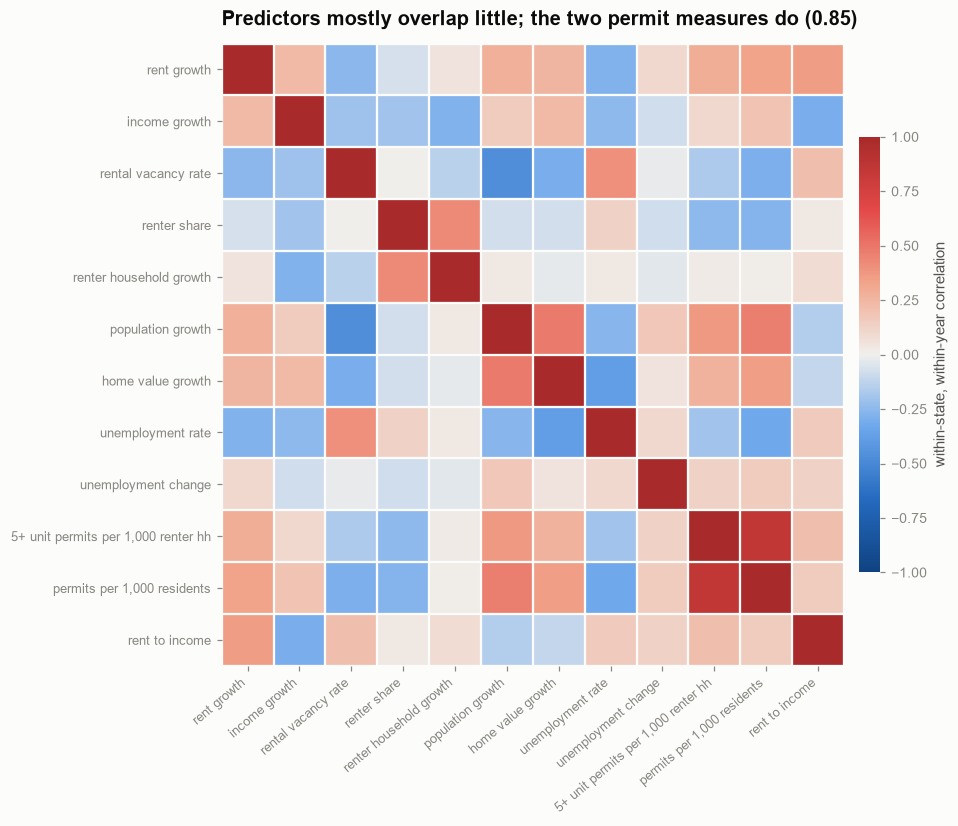

largest off-diagonal within correlation: 0.85 (5+ unit permits per 1,000 renter hh with permits per 1,000 residents)


,rent growth,income growth,rental vacancy rate,renter share,renter household growth,population growth,home value growth,unemployment rate,unemployment change,"5+ unit permits per 1,000 renter hh","permits per 1,000 residents",rent to income
VIF,1.7,1.5,1.6,1.4,1.4,1.8,1.5,1.5,1.1,3.9,4.6,1.7


In [2]:
cc = sup_b.dropna(subset=core + ["dy", "y_origin", "y_lag1"]).reset_index(drop=True)
w = two_way_demean(cc, core + ["dy", "y_origin"])
cm = w[core].corr()

fig, ax = plt.subplots(figsize=(8.8, 7.4))
im = ax.imshow(cm.values, cmap=DIVERGING, vmin=-1, vmax=1)
lab = [nice[c] for c in core]
ax.set_xticks(range(len(core)), lab, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(len(core)), lab, fontsize=8.5)
ax.set_xticks(np.arange(-.5, len(core), 1), minor=True); ax.set_yticks(np.arange(-.5, len(core), 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=1.5); ax.grid(which="major", visible=False); ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02); cb.set_label("within-state, within-year correlation", color=INK_2); cb.outline.set_visible(False)
off = cm.where(~np.eye(len(core), dtype=bool)).abs().stack()
pair = off.idxmax()
ax.set_title(f"Predictors mostly overlap little; the two permit measures do ({off.max():.2f})")
save_figure(fig, "05_predictor_correlations")
plt.show()
print(f"largest off-diagonal within correlation: {off.max():.2f} ({nice[pair[0]]} with {nice[pair[1]]})")
v = vif(w[core]).rename(index=nice).round(1)
display(v.to_frame("VIF").T)

## 2. What relates to next year's change in severe burden?

For each feature at the origin, the within correlation with the change in severe burden from the origin year to the next, with a 95
percent interval from resampling whole states (500 times). The first row is the burden's own level at the origin relative to the
state's norm: mean reversion. Every other feature is a candidate predictor.

In [3]:
def within_corr(sup, outcome, feats, extra=(), n=500):
    rows = []
    for f in list(extra) + list(feats):
        d = sup[[f, outcome, "state_fips", "origin_year"]].dropna().reset_index(drop=True)
        z = two_way_demean(d, [f, outcome])
        r, lo, hi = cluster_bootstrap_corr(z[f], z[outcome], d.state_fips, n=n)
        rows.append({"feature": f, "n": len(d), "corr": r, "lo": lo, "hi": hi})
    t = pd.DataFrame(rows).set_index("feature")
    t["significant"] = (t.lo > 0) | (t.hi < 0)
    return t

res_b = within_corr(sup_b, "dy", ext, extra=["y_origin"])
res_b.index = [("level at origin (mean reversion)" if i == "y_origin" else nice[i]) for i in res_b.index]
display(res_b.round(2))

,n,corr,lo,hi,significant
level at origin (mean reversion),612,-0.59,-0.64,-0.53,True
rent growth,510,0.10,0.02,0.17,True
income growth,510,0.11,-0.02,0.24,False
rental vacancy rate,612,-0.01,-0.12,0.10,False
renter share,612,0.01,-0.09,0.10,False
renter household growth,510,-0.08,-0.19,0.04,False
population growth,510,0.13,0.06,0.19,True
home value growth,510,0.13,0.05,0.20,True
unemployment rate,612,-0.08,-0.13,-0.03,True
unemployment change,561,0.08,-0.02,0.17,False


## 3. What relates to next year's rent growth?

Same exercise for rent growth one year ahead. The first row is rent growth at the origin (momentum).

,n,corr,lo,hi,significant
rent growth at origin (momentum),510,-0.11,-0.22,0.03,False
income growth,510,0.04,-0.09,0.19,False
rental vacancy rate,510,-0.25,-0.35,-0.15,True
renter share,510,-0.15,-0.27,-0.02,True
renter household growth,510,-0.05,-0.18,0.05,False
population growth,510,0.31,0.23,0.38,True
home value growth,510,0.23,0.16,0.31,True
unemployment rate,510,-0.23,-0.33,-0.13,True
unemployment change,510,0.03,-0.07,0.13,False
"5+ unit permits per 1,000 renter hh",510,0.14,0.00,0.28,True


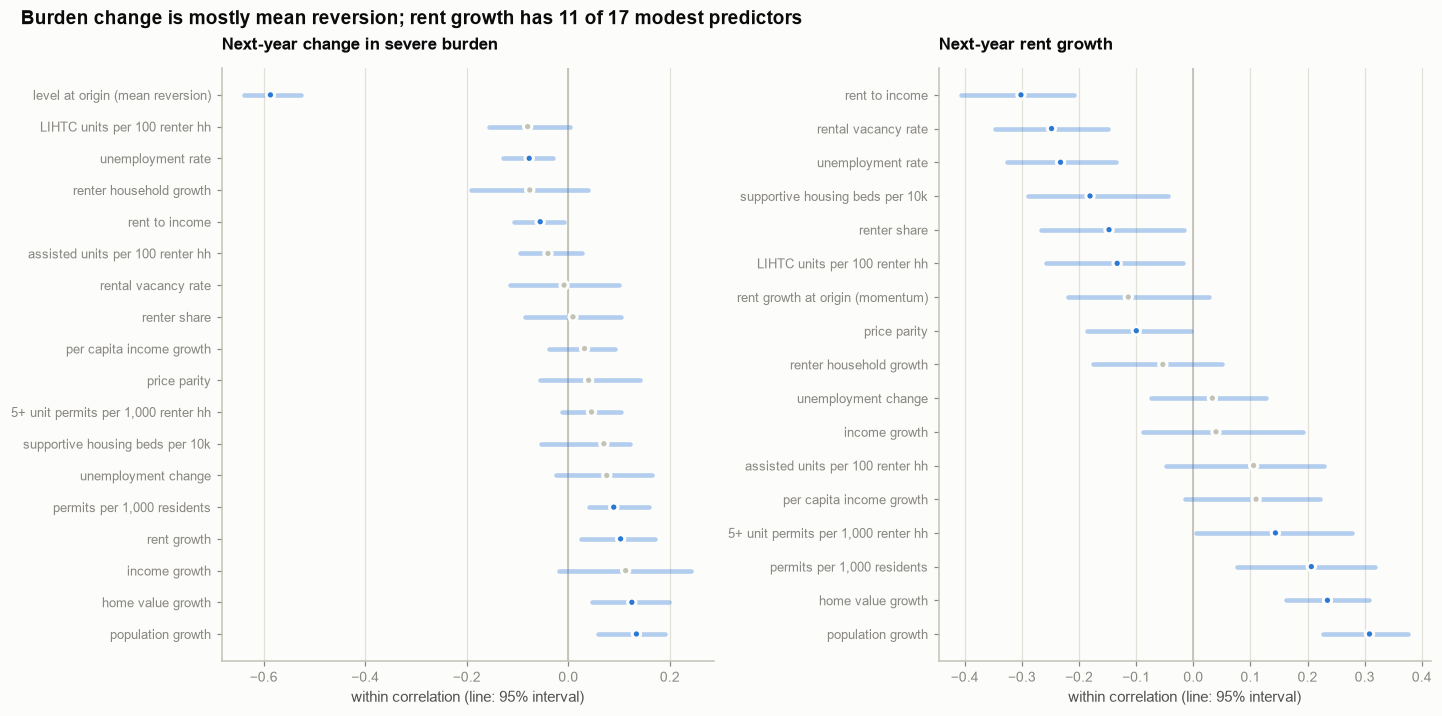

In [4]:
res_r = within_corr(sup_r, "y_target", [f for f in ext if f != "rent_growth_pct"], extra=["y_origin"])
res_r.index = [("rent growth at origin (momentum)" if i == "y_origin" else nice[i]) for i in res_r.index]
display(res_r.round(2))

def dotplot(ax, t, title, order):
    t = t.loc[order]
    y = np.arange(len(t))[::-1]
    ax.axvline(0, color=BASELINE, lw=1.2, zorder=1)
    for yi, (_, r) in zip(y, t.iterrows()):
        ax.plot([r.lo, r.hi], [yi, yi], color=SERIES[0], alpha=0.35, lw=3, solid_capstyle="round", zorder=2)
    ax.scatter(t["corr"], y, s=30, color=[SERIES[0] if s else "#c3c2b7" for s in t.significant], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_yticks(y, t.index, fontsize=8.5)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("within correlation (line: 95% interval)")

order_b = res_b["corr"].sort_values().index.tolist()
order_r = res_r["corr"].sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
dotplot(axes[0], res_b, "Next-year change in severe burden", order_b)
dotplot(axes[1], res_r, "Next-year rent growth", order_r)
nb_sig, nr_sig = int(res_b.significant.sum()), int(res_r.significant.sum())
fig.suptitle(f"Burden change is mostly mean reversion; rent growth has {nr_sig} of {len(res_r)} modest predictors",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
save_figure(fig, "05_within_correlations")
plt.show()

## 4. Timing: do the predictors lead the burden or move with it?

Correlation of the year's change in severe burden with the predictor in the same year (lag 0, not usable for a forecast made
before the year ends) and one, two, and three years earlier (usable). Within state and year.

lag (years earlier),0,1,2,3
predictor,,,,
income growth,-0.27,0.11,-0.00,0.06
rent growth,0.05,0.10,-0.01,0.15
unemployment change,0.10,0.08,-0.08,0.09


n  corr    95% interval  separates from zero
predictor           lag (years earlier)                                                
rent growth         0                    612  0.05   -0.05 to 0.15                False
                    1                    510  0.10    0.02 to 0.18                 True
                    2                    408 -0.01   -0.14 to 0.13                False
                    3                    357  0.15   -0.03 to 0.33                False
income growth       0                    612 -0.27  -0.40 to -0.14                 True
                    1                    510  0.11   -0.02 to 0.24                False
                    2                    408 -0.00   -0.15 to 0.16                False
                    3                    357  0.06   -0.05 to 0.19                False
unemployment change 0                    612  0.10    0.02 to 0.18                 True
                    1                    561  0.08   -0.02 to 0.17                False
                    2                    510 -0.08   -0.21 to 0.06                False
                    3                    459  0.09    0.02 to 0.16                 True

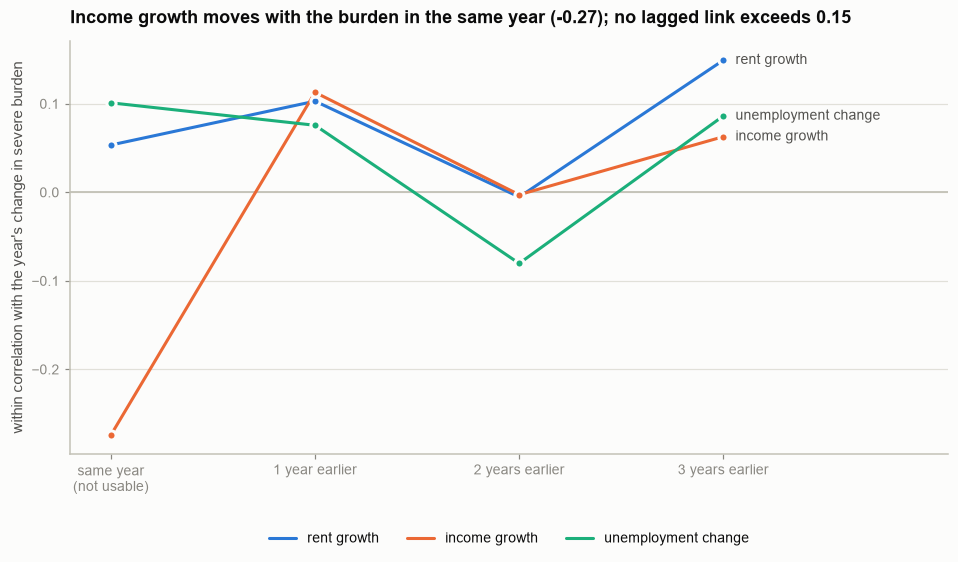

In [5]:
wide = lambda c: panel[panel.acs_available == 1].pivot(index="state_fips", columns="year", values=c).reindex(columns=range(2010, 2026))
bur = wide(TARGET)
dbur = bur - bur.shift(1, axis=1)
preds = {"rent growth": wide("rent_growth_pct"), "income growth": wide("income_growth_pct"), "unemployment change": panel.pivot(index="state_fips", columns="year", values="unemployment_rate_change_pp")}
rows = []
for name, X in preds.items():
    for k in range(0, 4):
        long = pd.DataFrame({"dy": dbur.stack(), "x": X.shift(k, axis=1).stack()}).dropna().reset_index()
        long.columns = ["state_fips", "year", "dy", "x"]
        z = two_way_demean(long, ["dy", "x"], time="year")
        r, lo, hi = cluster_bootstrap_corr(z.x, z.dy, long.state_fips, n=300)
        rows.append({"predictor": name, "lag (years earlier)": k, "n": len(long), "corr": r, "lo": lo, "hi": hi})
lag = pd.DataFrame(rows)
lag["95% interval"] = lag.apply(lambda r: f"{r['lo']:.2f} to {r['hi']:.2f}", axis=1)
lag["separates from zero"] = (lag.lo > 0) | (lag.hi < 0)
display(lag.pivot(index="predictor", columns="lag (years earlier)", values="corr").round(2))
display(lag[["predictor", "lag (years earlier)", "n", "corr", "95% interval", "separates from zero"]].round(2).set_index(["predictor", "lag (years earlier)"]))

fig, ax = plt.subplots(figsize=(8.6, 5))
for (name, g), color in zip(lag.groupby("predictor", sort=False), SERIES[:3]):
    ax.plot(g["lag (years earlier)"], g["corr"], color=color)
    for _, r in g.iterrows():
        dot(ax, r["lag (years earlier)"], r["corr"], color)
    end_label(ax, 3, g["corr"].iloc[-1], name, dx=8)
ax.axhline(0, color=BASELINE, lw=1.2, zorder=1)
ax.set_xticks([0, 1, 2, 3], ["same year\n(not usable)", "1 year earlier", "2 years earlier", "3 years earlier"])
ax.set_xlim(-0.2, 4.1)
ax.set_ylabel("within correlation with the year's change in severe burden")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Line2D([0], [0], color=c) for c in SERIES[:3]], labels=list(preds), loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
c0 = lag[lag["lag (years earlier)"] == 0].set_index("predictor")["corr"]
mx = lag[lag["lag (years earlier)"] >= 1]["corr"].abs().max()
ax.set_title(f"Income growth moves with the burden in the same year ({c0['income growth']:.2f}); no lagged link exceeds {mx:.2f}", fontsize=11.5)
save_figure(fig, "05_timing")
plt.show()

## 5. Do the results survive the post-2021 regime, and what do shared sources do?

The same within correlations with next-year burden change, leaving out origins whose target year is 2021, 2022, or 2023.
Then the correlation between ACS growth and the HUD series that share its source, which is why the exclusion rules keep
them apart.

In [6]:
keep = ~sup_b.target_year.isin([2021, 2022, 2023])
res_b2 = within_corr(sup_b[keep].reset_index(drop=True), "dy", ext, extra=["y_origin"], n=300)
res_b2.index = res_b.index
cmp_ = pd.DataFrame({"all origins": res_b["corr"], "excluding target years 2021-23": res_b2["corr"], "significant, all": res_b.significant,
                     "significant, excluding": res_b2.significant}).round(2)
display(cmp_)

fm = panel.pivot(index="state_fips", columns="year", values="fmr_2br_growth_pct")
rg = panel.pivot(index="state_fips", columns="year", values="rent_growth_pct")
inc_h = panel.pivot(index="state_fips", columns="year", values="hud_median_family_income")
inc_h = 100 * (inc_h / inc_h.shift(1, axis=1) - 1)
ig = panel.pivot(index="state_fips", columns="year", values="income_growth_pct")
def wcorr(a, b):
    d = pd.DataFrame({"a": a.stack(), "b": b.stack()}).dropna().reset_index(); d.columns = ["state_fips", "year", "a", "b"]
    z = two_way_demean(d, ["a", "b"], time="year")
    return z.a.corr(z.b), len(d)
r1, n1 = wcorr(fm, rg); r2, n2 = wcorr(inc_h, ig)
display(pd.DataFrame({"pair": ["FMR 2-bedroom growth with ACS rent growth", "HUD median family income growth with ACS income growth"],
                      "within correlation": [r1, r2], "state-years": [n1, n2]}).round(2))

,all origins,excluding target years 2021-23,"significant, all","significant, excluding"
level at origin (mean reversion),-0.59,-0.57,True,True
rent growth,0.10,0.04,True,False
income growth,0.11,0.11,False,False
rental vacancy rate,-0.01,0.01,False,False
renter share,0.01,-0.00,False,False
renter household growth,-0.08,-0.09,False,False
population growth,0.13,0.12,True,True
home value growth,0.13,0.07,True,False
unemployment rate,-0.08,-0.03,True,False
unemployment change,0.08,0.10,False,True


,pair,within correlation,state-years
0,FMR 2-bedroom growth with ACS rent growth,0.18,612
1,HUD median family income growth with ACS incom...,0.09,612


## 6. Can the mean reversion be used out of sample?

The within correlation of -0.59 between the burden's level at the origin and its next change uses state means taken over the
whole sample and removes the common year effect, so it overstates what a forecaster could do. The rolling-origin test is the
fair check: forecast = (1 - w) times the origin value plus w times the state's own mean of the targets known at the origin. w = 0
is persistence; w = 1 is the state history mean. MAE ratios below 1 beat persistence.

In [7]:
from evaluation import run_backtest, summarize
from models.baselines import Persistence, ShrinkToStateMean

frames = []
for h in (1, 2, 3):
    sup = make_supervised(panel, TARGET, h, core)
    for m in [Persistence()] + [ShrinkToStateMean(w) for w in (0.25, 0.5, 0.75, 1.0)]:
        frames.append(run_backtest(m, sup, TARGET, h, first_origin=2015))
bt = pd.concat(frames, ignore_index=True)
full, ex = summarize(bt), summarize(bt, exclude_years=(2021,))
show = full[["horizon", "model", "mae", "mae_vs_persistence", "origins_won_vs_persistence", "dm_p"]].copy()
show["ratio ex 2021"] = ex.set_index(["horizon", "model"]).mae_vs_persistence.reindex(pd.MultiIndex.from_frame(show[["horizon", "model"]])).to_numpy()
display(show.round(3).set_index(["horizon", "model"]))
best = show[show.model != "persistence"].sort_values(["horizon", "mae"]).groupby("horizon").head(1)
print("best shrink weight by horizon:", dict(zip(best.horizon, best.model)), "| MAE ratios:", dict(zip(best.horizon, best.mae_vs_persistence.round(3))))

mae  mae_vs_persistence  origins_won_vs_persistence   dm_p  ratio ex 2021
horizon model                                                                                   
1       shrink_0.25  1.089               0.998                       0.571  0.970          1.021
        persistence  1.091               1.000                         NaN    NaN          1.000
        shrink_0.50  1.165               1.068                       0.429  0.518          1.124
        shrink_0.75  1.305               1.196                       0.286  0.233          1.291
        shrink_1.00  1.508               1.382                       0.286  0.076          1.505
2       shrink_0.50  1.340               0.945                       0.500  0.593          1.074
        shrink_0.25  1.351               0.953                       0.667  0.331          1.010
        shrink_0.75  1.394               0.983                       0.500  0.921          1.195
        persistence  1.418               1.000                         NaN    NaN          1.000
        shrink_1.00  1.498               1.056                       0.500  0.802          1.348
3       shrink_1.00  1.497               0.897                       0.600  0.414          0.923
        shrink_0.75  1.504               0.902                       0.600  0.457          0.926
        shrink_0.50  1.540               0.923                       0.600  0.457          0.943
        shrink_0.25  1.591               0.954                       0.600  0.450          0.966
        persistence  1.668               1.000                         NaN    NaN          1.000

best shrink weight by horizon: {1: 'shrink_0.25', 2: 'shrink_0.50', 3: 'shrink_1.00'} | MAE ratios: {1: 0.998, 2: 0.945, 3: 0.897}


## Findings


1. **Predictors mostly overlap little, except the two permit measures.** Within state and year, the twelve core predictors have
   variance inflation factors of 1.1 to 1.8, with the two permit measures the exception (5+ unit permits per renter household
   and permits per resident correlate 0.85; VIF 3.9 and 4.6). Use one at a time in the linear models.
2. **Next year's change in severe burden is mostly mean reversion.** The burden's level at the origin, relative to the state's
   norm, has a within correlation of -0.59 (95 percent interval -0.64 to -0.53) with the next change. No economic predictor
   exceeds 0.13 in absolute value: population growth and home value growth (+0.13), rent growth (+0.10), permits per
   resident (+0.09), unemployment rate (-0.08), rent to income (-0.06). Seven of 18 separate from zero (including mean
   reversion), and leaving out target years 2021 to 2023 leaves mean reversion, population growth, permits per resident,
   rent to income, unemployment change, and LIHTC supply. This is the signal-versus-noise finding from notebook 1.2 seen from the
   predictor side: a reading that was high by chance tends to be followed by a lower one, and little else moves the change.
3. **The mean reversion is not usable at one year.** The -0.59 is an in-sample association (state means from the full sample,
   common year effects removed). In the rolling-origin test, shrinking the forecast toward the state's own training mean
   gives no gain at one year (best weight 0.25: MAE ratio 0.998 against persistence; weight 0.5: 1.07; the state mean: 1.38).
   At two years a weight of 0.5 gives 0.945, and at three years the state mean gives 0.897, winning 60 percent of origins, but
   neither is statistically distinguishable from persistence (Diebold-Mariano p 0.59 and 0.41, with only 5 to 7 origins).
   Longer horizons favor a state-level anchor because more of the error is noise.
4. **Rent growth has real predictors, with the signs theory expects.** Eleven of 17 separate from zero for next-year rent growth (5+ unit permits and price parity only just):
   population growth +0.31, rent to income -0.30, rental vacancy rate -0.25, unemployment rate -0.23, home value growth
   +0.23, permits per resident +0.21, supportive housing beds -0.18, renter share -0.15, LIHTC supply -0.13, price parity -0.10,
   5+ unit permits +0.14. Rent growth rises where population and home values are growing and falls where rent already takes
   a large share of income, vacancy is high, or unemployment is high. Momentum (-0.11) is not distinguishable from zero.
5. **Timing.** The burden's change moves with income growth in the same year (-0.27) but only 0.05 with the same year's rent
   growth, and every lagged link is 0.15 or less and mostly indistinguishable from zero. There is no strong leading relationship
   for a one-year forecast of the burden to use, unlike for rent growth.
6. **Parts of this depend on the post-2021 regime.** Excluding target years 2021 to 2023, the rent growth, home value growth, and
   unemployment rate links with the burden lose significance, while mean reversion (-0.57), population growth (+0.12), permits
   per resident, and rent to income hold.
7. **Shared sources are independent at the growth level.** The FMR 2-bedroom growth and ACS rent growth have a within correlation
   of only 0.18, and HUD median family income growth and ACS income growth 0.09, although their levels correlate above 0.95
   (notebook validation). The exclusion rule (never pair them) is therefore conservative. It stays, but Part 2 may test FMR
   growth as an alternative to ACS rent growth, not beside it.

**Part 1 gate: what to confirm**

| Decision | Recommendation | Why |
|---|---|---|
| Primary target | Keep annual ACS severe burden, with rent burden at 30 percent and **rent growth** as secondary targets | Burden is the policy outcome but mostly noise year to year; rent growth is where predictors carry signal and where the ML bake-off has most room |
| Validated horizons | 1 to 3 years, reported separately | Persistence is hard to beat at one year; a state-level anchor helps by three years |
| Feature sets | Keep `core` and `extended`; use one permit measure at a time in linear models | Overlap is low except the permit pair; subsidized supply measures are weak but carry some rent-growth signal |
| Predictors to prioritize | Population growth, home value growth, rent to income, vacancy, unemployment rate, permits per resident | They separate from zero for rent growth and, partly, for the burden |
| AHNI weak components | Decide: keep or drop vacancy and the rent-growth gap | They do not fit the other five (notebook 1.4) |
| Model emphasis for the burden | Expect little gain over persistence at one year; the Bayesian measurement-error model and a state anchor are the candidates | Sampling noise sets a floor of 0.61 against 1.09 for persistence |

**Caveats.** Within correlations are in-sample descriptions, not forecast accuracy (section 6 is the out-of-sample check). The
bootstrap resamples states, which assumes states are independent of each other, and cross-state dependence is tested in Part 2.
Predictors that are themselves survey estimates carry sampling error, which pulls correlations toward zero.